In [17]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
n_chips = 5000

# Simulate realistic semiconductor wafer test dataset
data = {
    'wafer_id': np.random.randint(101, 121, size=n_chips),  # 20 unique silicon wafers
    'chip_id': [f"CHIP_{i:04d}" for i in range(n_chips)],
    'voltage_leakage_mA': np.random.normal(loc=1.2, scale=0.3, size=n_chips),  # Current leakage
    'thermal_resistance_C_W': np.random.normal(loc=45.0, scale=8.0, size=n_chips), # Heat dissipation
    'frequency_GHz': np.random.normal(loc=3.4, scale=0.5, size=n_chips), # Clock speed
}

df = pd.DataFrame(data)

# --- INJECTING ARTIFICIAL DATA CORRUPTIONS (For Cleaning Pipeline) ---

# 1. Introduce Missing Values (NaN) due to sensor timeouts / logging issues
df.loc[df.sample(frac=0.03).index, 'voltage_leakage_mA'] = np.nan
df.loc[df.sample(frac=0.02).index, 'frequency_GHz'] = np.nan

# 2. Introduce Outliers due to equipment calibration faults
df.loc[df.sample(n=15).index, 'thermal_resistance_C_W'] = 999.0  # Impossible thermal spikes
df.loc[df.sample(n=10).index, 'frequency_GHz'] = -1.0             # Negative frequency anomaly

# Display the first 5 rows of the raw dataset
df.head()


,wafer_id,chip_id,voltage_leakage_mA,thermal_resistance_C_W,frequency_GHz
0,107,CHIP_0000,1.420687,40.946921,3.121767
1,120,CHIP_0001,1.734540,46.918982,3.658605
2,115,CHIP_0002,0.703013,56.883819,3.621946
3,111,CHIP_0003,1.042666,28.620503,4.010583
4,108,CHIP_0004,0.979409,43.234170,3.339749


In [18]:
# Check for missing values (NaN) in the dataset to locate sensor dropouts
print("=== Missing Values Summary ===")
print(df.isnull().sum())

# Display basic structural information about the data framework
print("\n=== Dataset Info ===")
df.info()


=== Missing Values Summary ===
wafer_id                    0
chip_id                     0
voltage_leakage_mA        150
thermal_resistance_C_W      0
frequency_GHz             100
dtype: int64

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   wafer_id                5000 non-null   int64  
 1   chip_id                 5000 non-null   str    
 2   voltage_leakage_mA      4850 non-null   float64
 3   thermal_resistance_C_W  5000 non-null   float64
 4   frequency_GHz           4900 non-null   float64
dtypes: float64(3), int64(1), str(1)
memory usage: 239.4 KB


In [19]:
# --- STEP 3: DATA CLEANING & RECTIFICATION ---

# 1. Handle Missing Values (Imputation using Median)
# We fill missing data with the median value of that specific test parameter
df['voltage_leakage_mA'] = df['voltage_leakage_mA'].fillna(df['voltage_leakage_mA'].median())
df['frequency_GHz'] = df['frequency_GHz'].fillna(df['frequency_GHz'].median())

# 2. Handle Equipment Anomalies & Impossible Outliers
# Remove rows where calibration caused impossible physical results (-1 GHz or 999 C/W)
df_clean = df[
    (df['thermal_resistance_C_W'] < 500.0) & 
    (df['frequency_GHz'] >= 0.0)
].copy()

# 3. Verify the final clean dataset structural status
print("=== Remaining Missing Values after Cleaning ===")
print(df_clean.isnull().sum())
print(f"\nOriginal Dataset Size: {len(df)} rows")
print(f"Cleaned Dataset Size : {len(df_clean)} rows")


=== Remaining Missing Values after Cleaning ===
wafer_id                  0
chip_id                   0
voltage_leakage_mA        0
thermal_resistance_C_W    0
frequency_GHz             0
dtype: int64

Original Dataset Size: 5000 rows
Cleaned Dataset Size : 4975 rows


In [20]:
# --- STEP 4: SEMICONDUCTOR QUALITY BINNING & CLASSIFICATION ---

def classify_chip(row):
    # Criteria for Class A (Premium Pro Chips): High frequency and low voltage leakage
    if row['frequency_GHz'] >= 3.6 and row['voltage_leakage_mA'] <= 1.1:
        return 'Class A (Premium Pro)'
    
    # Criteria for Defective Chips: Dangerous voltage leakage or high thermal resistance
    elif row['voltage_leakage_mA'] > 1.8 or row['thermal_resistance_C_W'] > 60.0:
        return 'Defective (Scrap)'
    
    # All remaining chips that meet safe operational standards
    else:
        return 'Class B (Standard)'

# Apply the classification function to each chip in the clean dataset
df_clean['quality_class'] = df_clean.apply(classify_chip, axis=1)

# Display the total distribution of manufactured chips by quality segment
print("=== Semiconductor Quality Classification Summary ===")
print(df_clean['quality_class'].value_counts())

# Calculate and display the global production yield rate (%)
yield_rate = (df_clean['quality_class'] != 'Defective (Scrap)').mean() * 100
print(f"\nGlobal Factory Yield Rate: {yield_rate:.2f}%")


=== Semiconductor Quality Classification Summary ===
quality_class
Class B (Standard)       4097
Class A (Premium Pro)     644
Defective (Scrap)         234
Name: count, dtype: int64

Global Factory Yield Rate: 95.30%


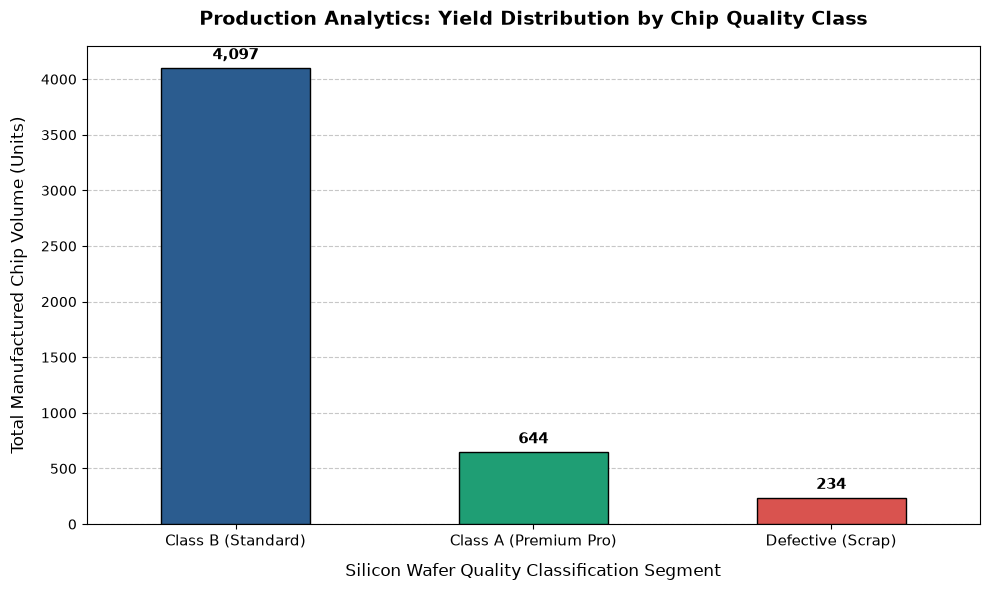

In [21]:
# --- STEP 5: PRODUCTION DATA VISUALIZATION ---

import matplotlib.pyplot as plt

# Define corporate/professional colors for the semiconductor segments
colors = ['#2b5c8f', '#1f9e74', '#d9534f']

# Setup the figure canvas size
plt.figure(figsize=(10, 6))

# Plot the distribution count of each chip quality class
class_counts = df_clean['quality_class'].value_counts()
class_counts.plot(kind='bar', color=colors, edgecolor='black', zorder=3)

# Style the chart with professional labels and infrastructure
plt.title('Production Analytics: Yield Distribution by Chip Quality Class', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Silicon Wafer Quality Classification Segment', fontsize=12, labelpad=10)
plt.ylabel('Total Manufactured Chip Volume (Units)', fontsize=12, labelpad=10)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)

# Display the exact volume counts on top of each bar
for index, value in enumerate(class_counts):
    plt.text(index, value + 50, f"{value:,}", ha='center', va='bottom', fontsize=11, fontweight='bold')

# Show the clean finalized production chart
plt.tight_layout()
plt.show()


In [22]:
# --- STEP 6: VERIFIED DATA EXPORT PIPELINE ---

# Save the finalized clean dataset into a structured CSV file
df_clean.to_csv('cleaned_semiconductor_wafer_data.csv', index=False)

print("=== Pipeline Execution Successful ===")
print("The verified laboratory production dataset has been successfully compiled and saved as:")
print("'cleaned_semiconductor_wafer_data.csv'")


=== Pipeline Execution Successful ===
The verified laboratory production dataset has been successfully compiled and saved as:
'cleaned_semiconductor_wafer_data.csv'
